# Đánh giá RetinaFace trên WIDER FACE validation
Đặt notebook tại thư mục gốc project, chọn kernel **.venv** và chạy từ trên xuống. Cần `matplotlib` và các thư viện project. Notebook dùng detector và lọc khung trùng của app. Kết quả là Precision/Recall tại một ngưỡng cố định trên subset validation. Đây là phép đánh giá của đồ án. AP Easy/Medium/Hard của benchmark dùng giao thức riêng.

In [7]:
from pathlib import Path
import csv
import json
import random

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from src.pipeline.inference import FacePipeline
from src.pipeline.preprocess_input import limit_size, load_image

ROOT = Path(r"C:\Users\NAO\face_detection_segmentation\data\raw\WIDER_FACE")
OUTPUT = Path("outputs/wider_face")

LIMIT = 200  # Đặt None nếu muốn chấm toàn bộ tập validation.
SEED = 42
CONFIDENCE = 0.50
NMS_IOU = 0.38
MATCH_IOU = 0.50

if not ROOT.is_dir():
    raise FileNotFoundError(f"Không tìm thấy thư mục gốc: {ROOT}")

image_folders = sorted(
    folder for folder in ROOT.rglob("images")
    if folder.is_dir()
    and any(part.lower() == "wider_val" for part in folder.relative_to(ROOT).parts)
)
label_files = sorted(
    file for file in ROOT.rglob("wider_face_val_bbx_gt.txt")
    if file.is_file()
)

print("Thư mục ảnh validation tìm được:")
for folder in image_folders:
    print(" ", folder)

print("File nhãn validation tìm được:")
for file in label_files:
    print(" ", file)

if len(image_folders) != 1 or len(label_files) != 1:
    raise ValueError(
        f"Tìm được {len(image_folders)} thư mục ảnh validation và "
        f"{len(label_files)} file nhãn. Cần đúng một thư mục ảnh "
        "thuộc WIDER_val và một file wider_face_val_bbx_gt.txt."
    )

IMAGES = image_folders[0]
LABELS = label_files[0]

print("\nĐã tìm thấy dữ liệu:")
print("IMAGES =", IMAGES)
print("LABELS =", LABELS)

Thư mục ảnh validation tìm được:
  C:\Users\NAO\face_detection_segmentation\data\raw\WIDER_FACE\WIDER_val\WIDER_val\images
File nhãn validation tìm được:
  C:\Users\NAO\face_detection_segmentation\data\raw\WIDER_FACE\wider_face_annotations\wider_face_split\wider_face_val_bbx_gt.txt

Đã tìm thấy dữ liệu:
IMAGES = C:\Users\NAO\face_detection_segmentation\data\raw\WIDER_FACE\WIDER_val\WIDER_val\images
LABELS = C:\Users\NAO\face_detection_segmentation\data\raw\WIDER_FACE\wider_face_annotations\wider_face_split\wider_face_val_bbx_gt.txt


## 1. Đọc nhãn và chọn mẫu cố định

In [8]:
def read_annotations(path):
    lines = iter(line.strip() for line in path.read_text(encoding="utf-8-sig").splitlines()
                 if line.strip())
    for name in lines:
        # Một số ảnh có 0 mặt đi kèm dòng toàn số 0.
        if name.split()[0].isdigit():
            if all(value == "0" for value in name.split()):
                continue
            raise ValueError(f"Dòng nhãn bất thường: {name}")
        count = int(next(lines))
        valid, ignored = [], []
        for _ in range(count):
            fields = list(map(int, next(lines).split()))
            x, y, width, height = fields[:4]
            if width > 0 and height > 0:
                boxes = ignored if fields[7] == 1 else valid
                boxes.append((x, y, x + width, y + height))
        yield name, valid, ignored


records = list(read_annotations(LABELS))
random.Random(SEED).shuffle(records)
selected = records[:LIMIT]
if not selected:
    raise ValueError("Cần chọn ít nhất một ảnh.")
missing = [name for name, _, _ in selected if not (IMAGES / name).is_file()]
if missing:
    raise FileNotFoundError(f"Thiếu {len(missing)} ảnh. Ví dụ: {missing[0]}")
print(f"Validation: {len(records)} ảnh có nhãn | chọn: {len(selected)} ảnh")
print(f"Bbox hợp lệ trong mẫu: {sum(len(valid) for _, valid, _ in selected)}")


Validation: 3226 ảnh có nhãn | chọn: 200 ảnh
Bbox hợp lệ trong mẫu: 2568


## 2. Ghép bbox và chạy thử 10 ảnh
Xét dự đoán theo confidence giảm dần. Mỗi bbox chuẩn hợp lệ ghép tối đa một dự đoán đạt IoU ≥ 0,50. Nếu không ghép được, bbox dự đoán đủ chồng lấn với một nhãn hợp lệ đã ghép được tính là FP. Các dự đoán còn lại chồng lấn đủ với nhãn invalid được bỏ qua.

In [9]:
def box_iou(a, b):
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    intersection = w * h
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - intersection
    return intersection / union if union > 0 else 0.0


def match_faces(faces, valid, ignored):
    matched = set()
    predictions = []
    for face in sorted(faces, key=lambda face: face.score, reverse=True):
        overlaps = [box_iou(face.bbox, box) for box in valid]
        eligible = [i for i, iou in enumerate(overlaps) if iou >= MATCH_IOU]
        available = [i for i in eligible if i not in matched]
        if available:
            matched.add(max(available, key=overlaps.__getitem__))
            status = "TP"
        elif not eligible and any(box_iou(face.bbox, box) >= MATCH_IOU for box in ignored):
            status = "ignored"
        else:
            status = "FP"
        predictions.append((face.bbox, status))
    missed = [box for i, box in enumerate(valid) if i not in matched]
    return predictions, missed


def evaluate_image(record, pipeline):
    name, valid, ignored = record
    image, _ = load_image(IMAGES / name)
    work, _ = limit_size(image, pipeline.cfg["preprocess"]["max_side"])
    sy, sx = work.shape[0] / image.shape[0], work.shape[1] / image.shape[1]
    scale_box = lambda box: tuple(value * factor for value, factor in zip(box, (sx, sy, sx, sy)))
    detections = pipeline._get_detector().detect(work, CONFIDENCE)
    faces = pipeline._clean_detections(detections, work.shape)
    predictions, missed = match_faces(faces, list(map(scale_box, valid)), list(map(scale_box, ignored)))
    return {
        "image": name,
        "tp": sum(status == "TP" for _, status in predictions),
        "fp": sum(status == "FP" for _, status in predictions),
        "fn": len(missed),
        "ignored": sum(status == "ignored" for _, status in predictions),
        "predictions": predictions,
        "missed": missed,
    }


pipeline = FacePipeline()
pipeline.cfg["detection"]["nms_iou_threshold"] = NMS_IOU
smoke = [evaluate_image(record, pipeline) for record in selected[:10]]
print(f"Chạy thử thành công {len(smoke)} ảnh trên {pipeline.device}.")
for row in smoke[:3]:
    print(row["image"], {key: row[key] for key in ("tp", "fp", "fn")})


Chạy thử thành công 10 ảnh trên cuda.
39--Ice_Skating/39_Ice_Skating_iceskiing_39_941.jpg {'tp': 1, 'fp': 0, 'fn': 0}
2--Demonstration/2_Demonstration_Demonstrators_2_488.jpg {'tp': 4, 'fp': 3, 'fn': 4}
57--Angler/57_Angler_peoplefishing_57_880.jpg {'tp': 2, 'fp': 0, 'fn': 0}


## 3. Chạy trên toàn bộ mẫu đã chọn và tính chỉ số

In [10]:
results = list(smoke)
for i, record in enumerate(selected[len(smoke):], start=len(smoke) + 1):
    results.append(evaluate_image(record, pipeline))
    if i % 25 == 0 or i == len(selected):
        print(f"Đã chấm {i}/{len(selected)} ảnh", flush=True)

counts = {key: sum(row[key] for row in results) for key in ("tp", "fp", "fn", "ignored")}
tp, fp, fn = (counts[key] for key in ("tp", "fp", "fn"))
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
summary = {
    "dataset": "WIDER FACE validation",
    "images_evaluated": len(results),
    "images_available": len(records),
    "seed": SEED,
    "detector": pipeline.cfg["detection"]["model"],
    "device": pipeline.device,
    "max_faces_per_image": pipeline.cfg["detection"]["max_faces"],
    "max_side": pipeline.cfg["preprocess"]["max_side"],
    "confidence": CONFIDENCE,
    "nms_iou": NMS_IOU,
    "match_iou": MATCH_IOU,
    **counts,
    "precision": precision,
    "recall": recall,
    "f1": f1,
}
print(f"Ảnh={len(results)} | TP={tp} | FP={fp} | FN={fn}")
print(f"Precision={precision:.2%} | Recall={recall:.2%} | F1={f1:.2%}")


Đã chấm 25/200 ảnh
Đã chấm 50/200 ảnh
Đã chấm 75/200 ảnh
Đã chấm 100/200 ảnh
Đã chấm 125/200 ảnh
Đã chấm 150/200 ảnh
Đã chấm 175/200 ảnh
Đã chấm 200/200 ảnh
Ảnh=200 | TP=1193 | FP=171 | FN=1375
Precision=87.46% | Recall=46.46% | F1=60.68%


## 4. Xem lỗi và xuất kết quả

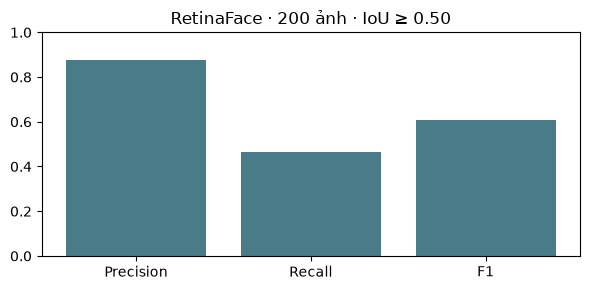

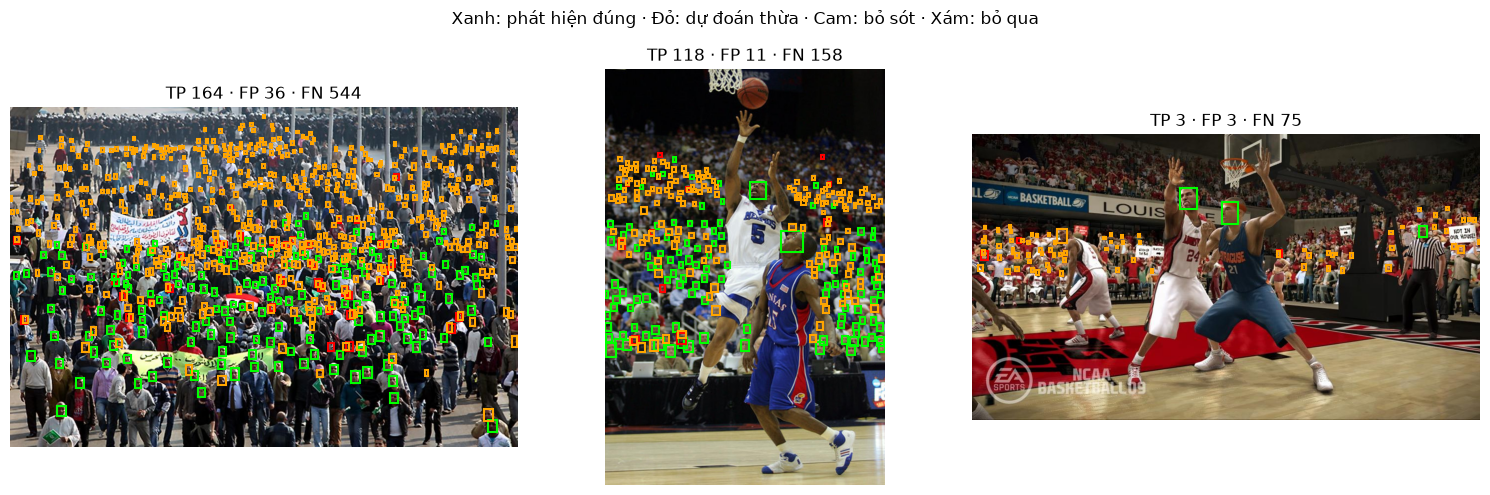

Đã lưu: C:\Users\NAO\face_detection_segmentation\outputs\wider_face


In [11]:
OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
columns = ["image", "tp", "fp", "fn", "ignored"]
with (OUTPUT / "per_image.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=columns, extrasaction="ignore")
    writer.writeheader()
    writer.writerows(results)

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Precision", "Recall", "F1"], [precision, recall, f1], color="#497b88")
ax.set_ylim(0, 1)
ax.set_title(f"RetinaFace · {len(results)} ảnh · IoU ≥ {MATCH_IOU:.2f}")
fig.tight_layout()
fig.savefig(OUTPUT / "metrics.png", dpi=150)
plt.show()

examples = sorted(results, key=lambda row: row["fp"] + row["fn"], reverse=True)[:3]
fig, axes = plt.subplots(1, len(examples), squeeze=False, figsize=(5 * len(examples), 5))
for axis, row in zip(axes[0], examples):
    image, _ = load_image(IMAGES / row["image"])
    work, _ = limit_size(image, pipeline.cfg["preprocess"]["max_side"])
    axis.imshow(work)
    colors = {"TP": "lime", "FP": "red", "FN": "orange", "ignored": "gray"}
    for box, status in row["predictions"] + [(box, "FN") for box in row["missed"]]:
        x1, y1, x2, y2 = box
        axis.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False,
                                 edgecolor=colors[status], linewidth=1.5))
    axis.set_title(f'TP {row["tp"]} · FP {row["fp"]} · FN {row["fn"]}')
    axis.axis("off")
fig.suptitle("Xanh: phát hiện đúng · Đỏ: dự đoán thừa · Cam: bỏ sót · Xám: bỏ qua")
fig.tight_layout()
fig.savefig(OUTPUT / "error_examples.png", dpi=150)
plt.show()
print("Đã lưu:", OUTPUT.resolve())
